# Ejercicios ensembling
En este ejercicio vas a realizar prediciones sobre un dataset de ciudadanos indios diabéticos. Se trata de un problema de clasificación en el que intentaremos predecir 1 (diabético) 0 (no diabético).

### 1. Carga las librerías que consideres comunes al notebook

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score

### 2. Lee los datos de [esta direccion](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv)
Los nombres de columnas son:
```Python
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
```

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']

df = pd.read_csv(url, names=names)

df.head()


,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   test    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
# obtén información del dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   test    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,preg,plas,pres,skin,test,mass,pedi,age,class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
# estadísticos descriptivos

,preg,plas,pres,skin,test,mass,pedi,age,class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


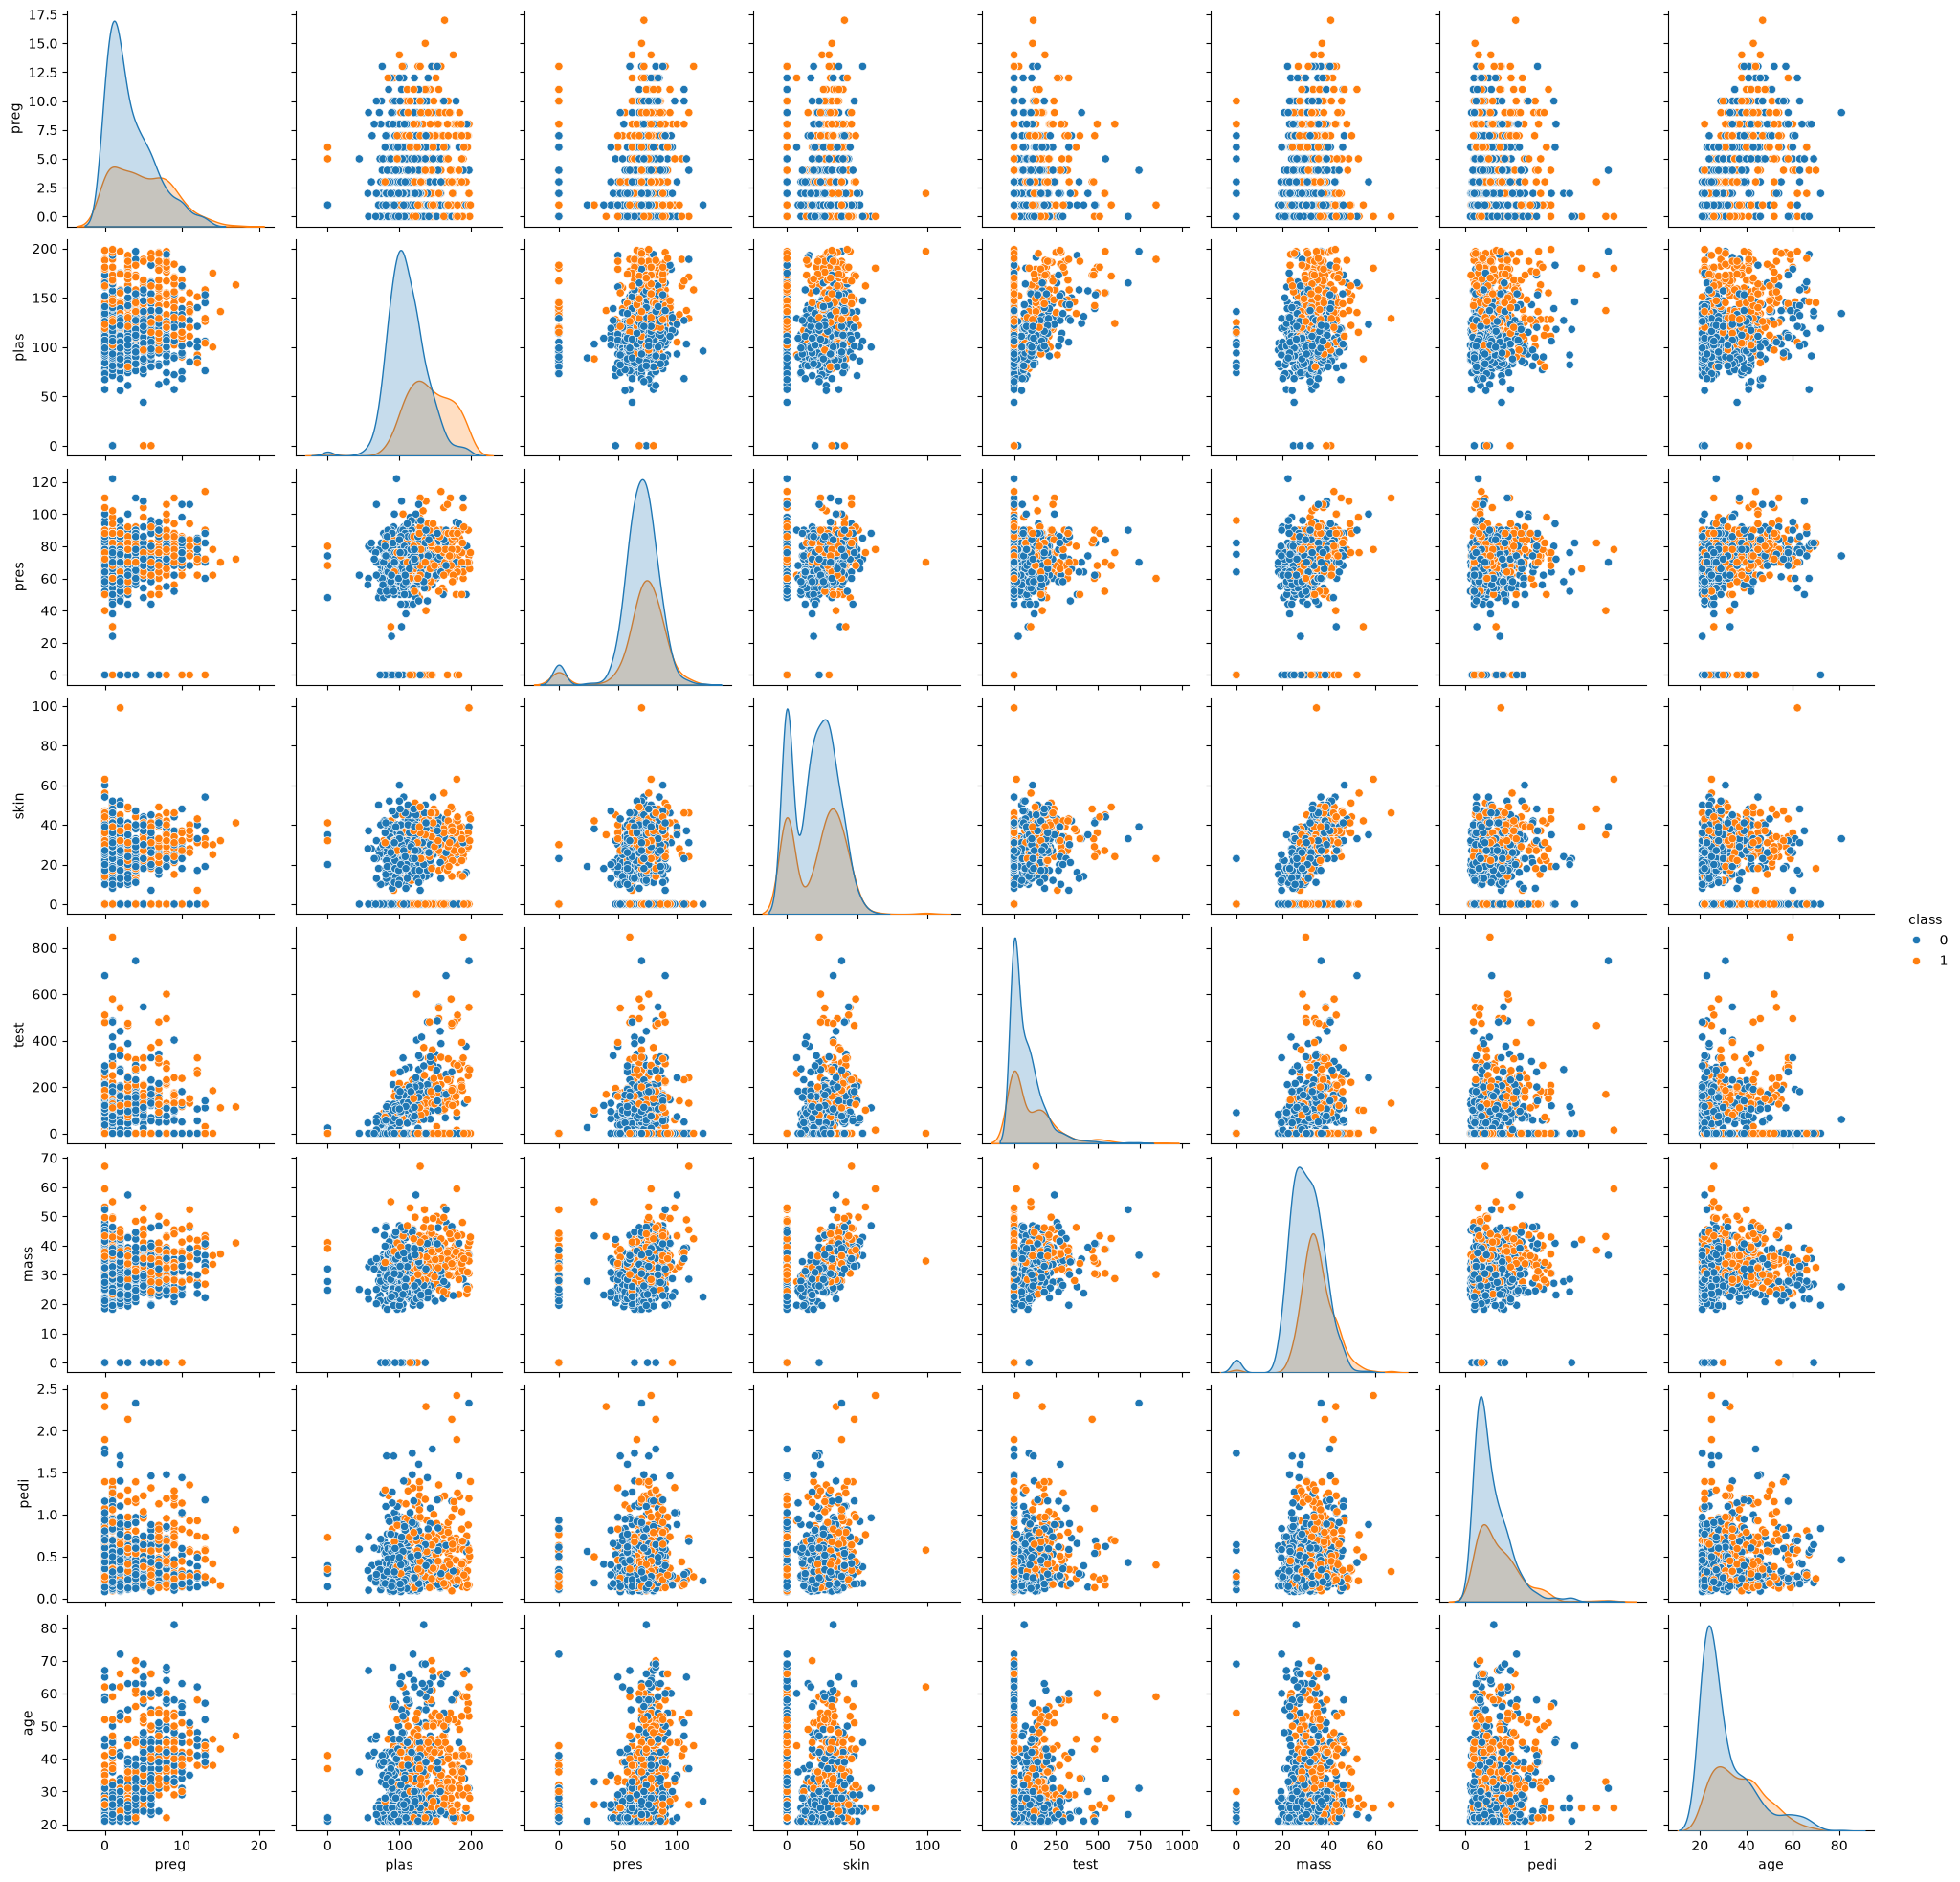

In [5]:
sns.pairplot(df, hue='class')

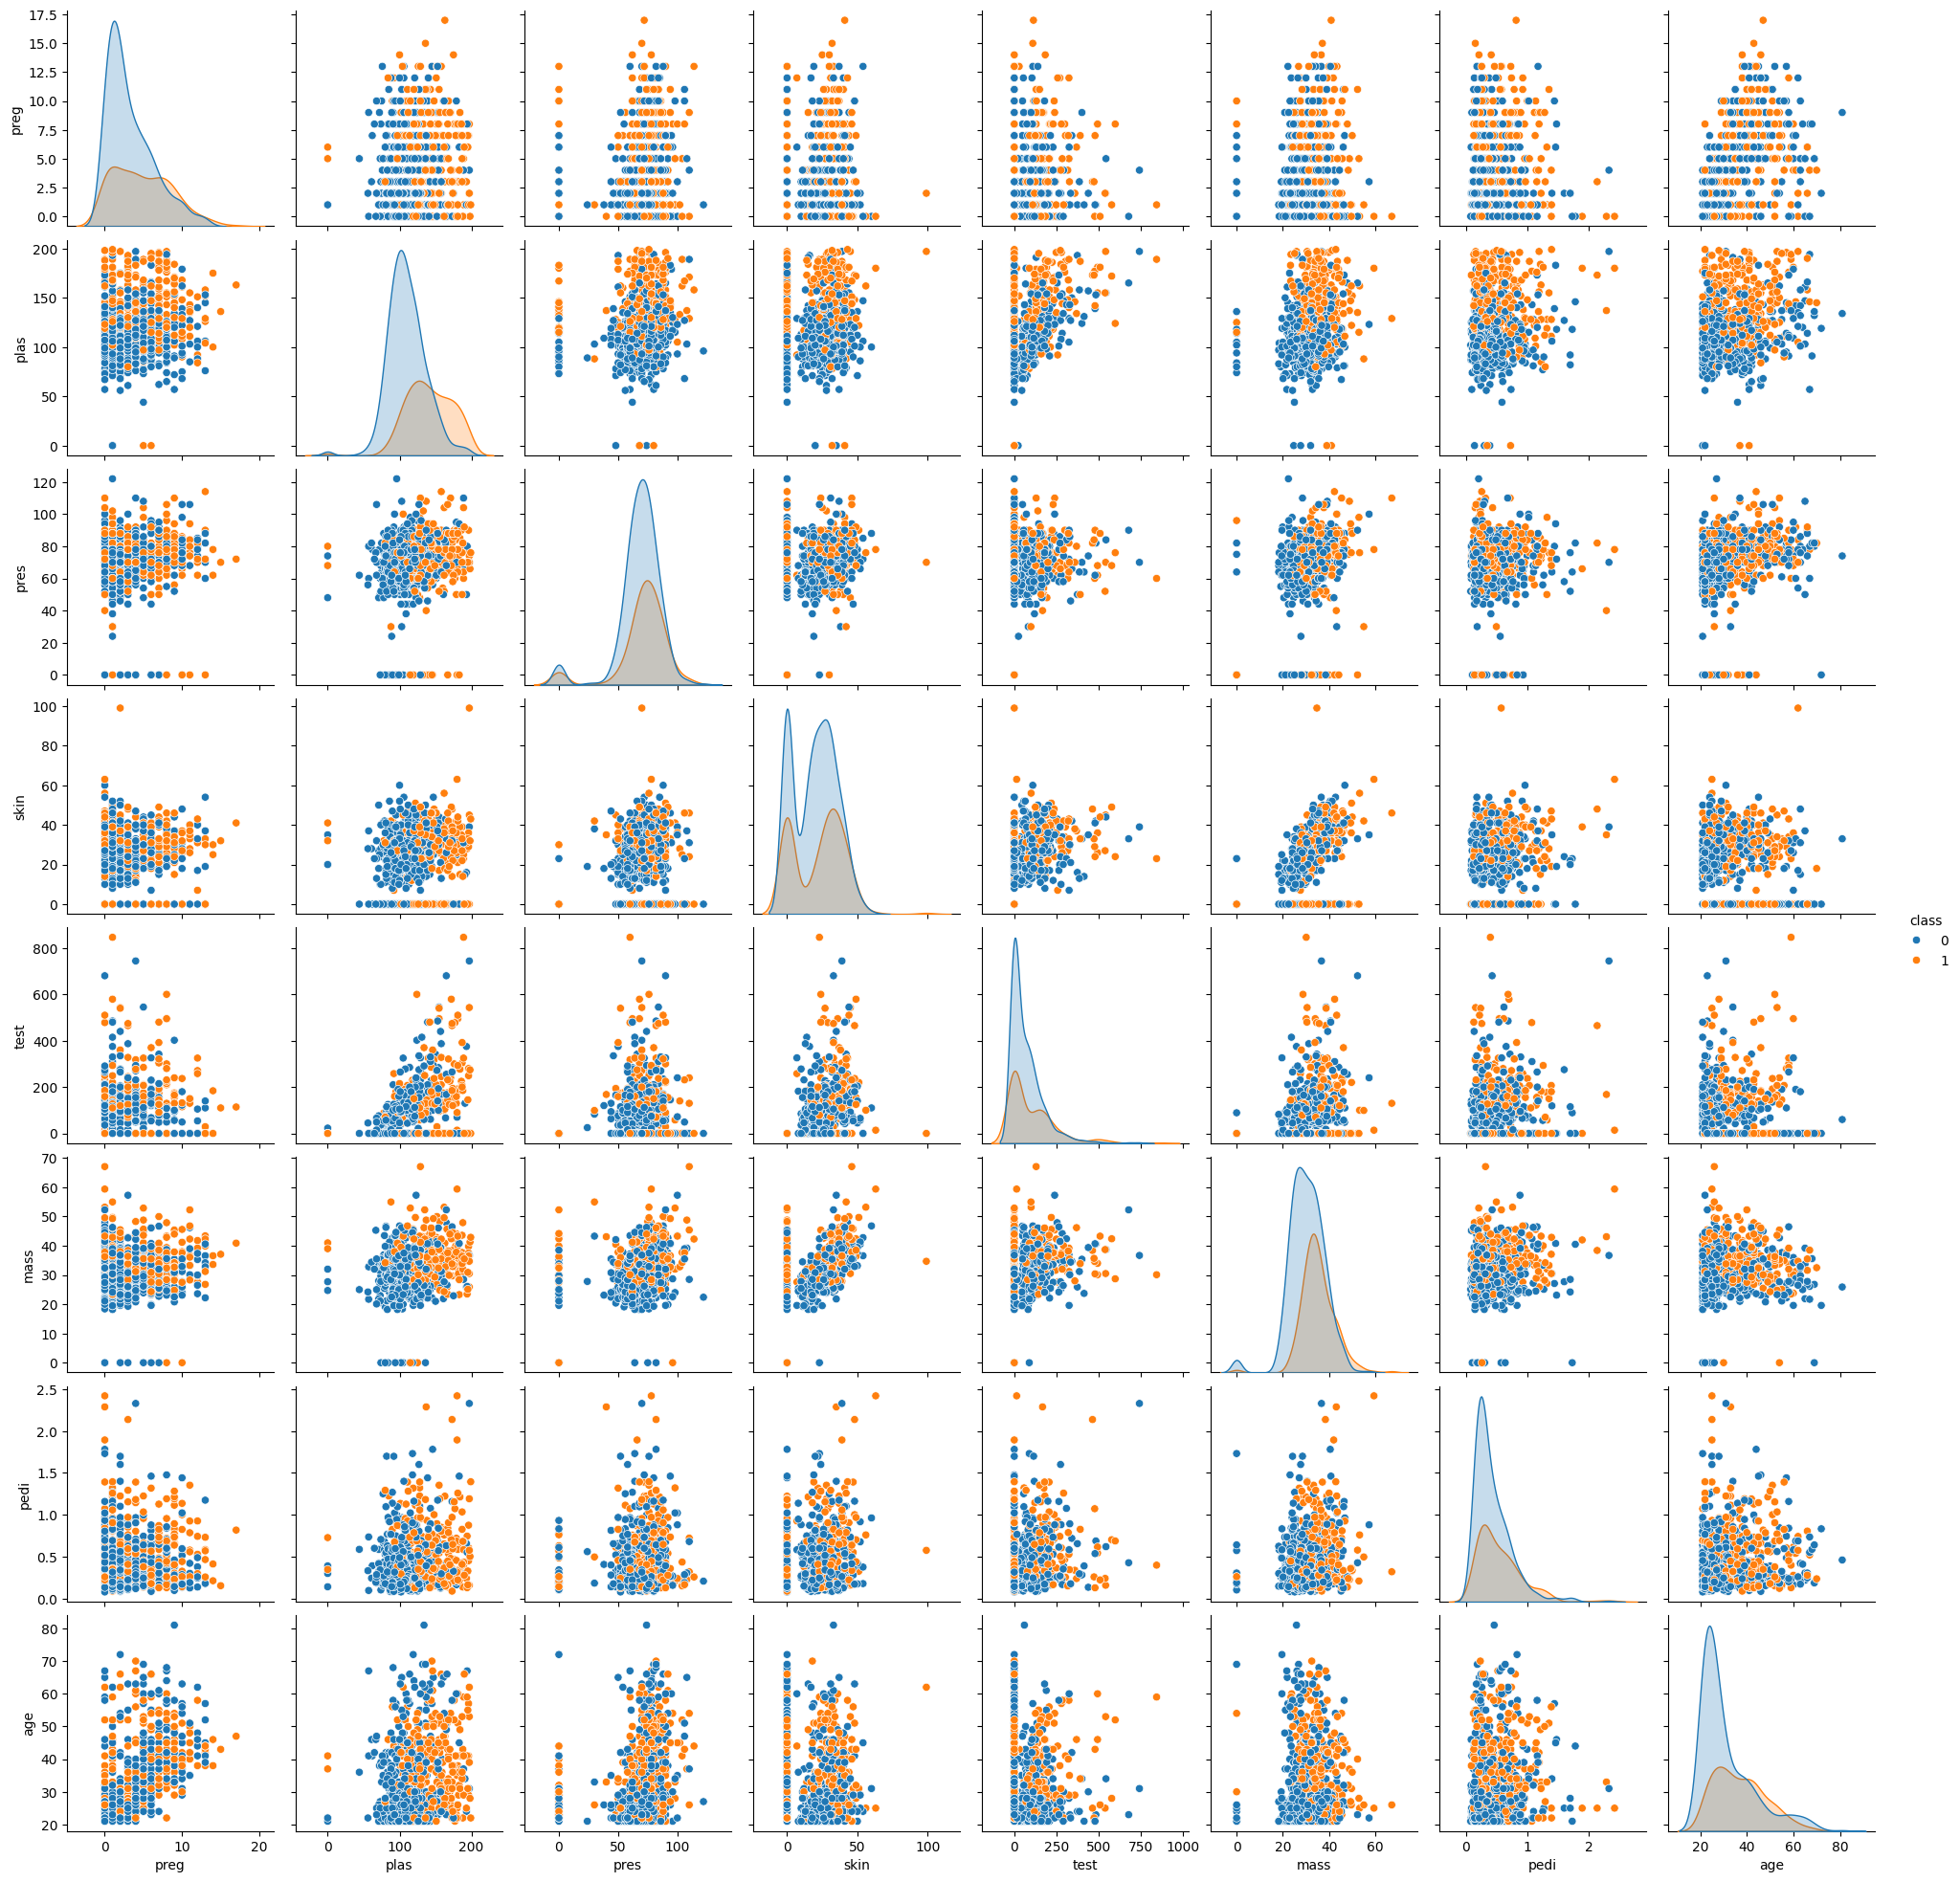

In [ ]:
# haz un pairplot y usa como hue 'class'

In [5]:
corr = df.corr(numeric_only=True)
corr

,preg,plas,pres,skin,test,mass,pedi,age,class
preg,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
plas,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
pres,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
skin,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
test,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
mass,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
pedi,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
class,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


<Axes: >

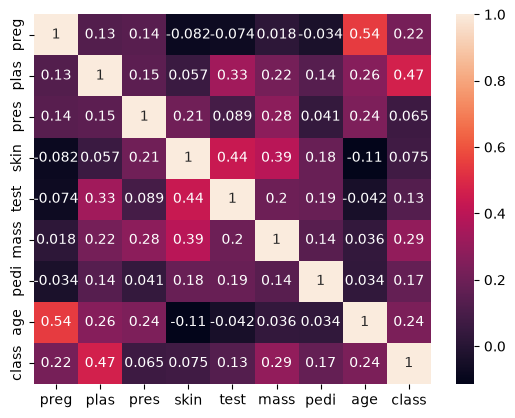

In [6]:
sns.heatmap(corr,annot=True)

<Axes: >

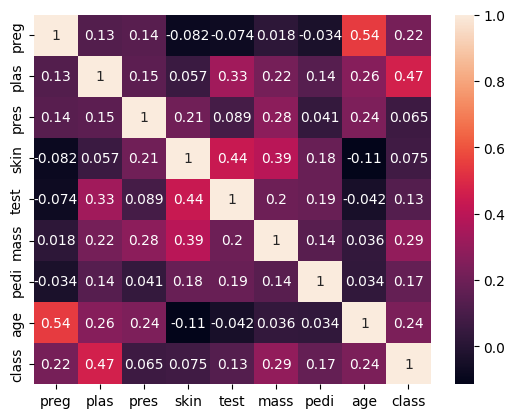

In [ ]:
# haz un heatmap con la correlación, muestra los datos en las cajitas

In [7]:
df['class'].value_counts(normalize=True)

class
0    0.651042
1    0.348958
Name: proportion, dtype: float64

In [ ]:
# haz un value counts de la clase normalizado

class
0    0.651042
1    0.348958
Name: proportion, dtype: float64

### 3. Bagging
Para este apartado tendrás que crear un ensemble utilizando la técnica de bagging ([BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)), mediante la cual combinarás 100 [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html). Recuerda utilizar también [cross validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) con 10 kfolds.

**Para este apartado y siguientes, no hace falta que dividas en train/test**, por hacerlo más sencillo. Simplemente divide tus datos en features y target.

Establece una semilla

In [ ]:
# define la X, la y y la semilla

In [4]:
X = df.drop('class', axis=1)
y = df['class']
seed = 42

In [3]:
# importa el árbol de clasificación, un clasificador de tipo bagging y un kfold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import KFold

In [ ]:


# haz un árbol de clasificación con profundidad 5
# haz un bagging classifier con ese tipo de árbol y 100 estimadores

In [43]:
tree = DecisionTreeClassifier(max_depth=5, random_state=seed)
tree.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [44]:
bagging = BaggingClassifier(estimator=tree,n_estimators=100,random_state=seed,n_jobs=-1)


In [ ]:
# usa KFold con 10 trozos
# mira en test qué índices tienen los trozos 

In [5]:
kfold = KFold(
    n_splits=10,
    shuffle=True,
    random_state=seed
)
kfold

KFold(n_splits=10, random_state=42, shuffle=True)

In [46]:
bagging_cvs = cross_val_score(bagging, X, y, cv=kfold, scoring='accuracy')

In [47]:
for i, (train_index, test_index) in enumerate(kfold.split(X)):
    print(f"Fold {i}:")
    # print(f"Train: index={train_index.min()}")
    print(f"Test: index={test_index.min()}")
    print(f"Test: index={test_index.max()}")

Fold 0:
Test: index=30
Test: index=764
Fold 1:
Test: index=2
Test: index=763
Fold 2:
Test: index=6
Test: index=762
Fold 3:
Test: index=11
Test: index=766
Fold 4:
Test: index=0
Test: index=767
Fold 5:
Test: index=12
Test: index=757
Fold 6:
Test: index=3
Test: index=753
Fold 7:
Test: index=36
Test: index=744
Fold 8:
Test: index=4
Test: index=765
Fold 9:
Test: index=1
Test: index=761


In [ ]:
# usa KFold con 10 trozos
# mira en test qué índices tienen los trozos 

# no te tiene por qué salir igual

Fold 0:
Test: index=0
Test: index=76
Fold 1:
Test: index=77
Test: index=153
Fold 2:
Test: index=154
Test: index=230
Fold 3:
Test: index=231
Test: index=307
Fold 4:
Test: index=308
Test: index=384
Fold 5:
Test: index=385
Test: index=461
Fold 6:
Test: index=462
Test: index=538
Fold 7:
Test: index=539
Test: index=615
Fold 8:
Test: index=616
Test: index=691
Fold 9:
Test: index=692
Test: index=767


In [48]:
# haz un crossvalscore del bagging classifier con scoring de accuracy
# calcula la media y stdv del score
# Validación cruzada
scores = cross_val_score(
    bagging,
    X,
    y,
    cv=kfold,
    scoring='accuracy'
)

In [49]:
# Resultados de cada fold
print("Scores:", scores)

# Media
print("Accuracy media: %.4f" % scores.mean())
bagging_cvs.mean()

# Desviación estándar
print("Desviación típica: %.4f" % scores.std())

Scores: [0.72727273 0.80519481 0.72727273 0.83116883 0.79220779 0.75324675
 0.83116883 0.75324675 0.65789474 0.76315789]
Accuracy media: 0.7642
Desviación típica: 0.0507


In [ ]:


# haz un crossvalscore del bagging classifier con scoring de accuracy
# calcula la media y stdv del score

[0.7012987  0.81818182 0.7012987  0.64935065 0.77922078 0.85714286
 0.83116883 0.85714286 0.72368421 0.77631579]
0.7694805194805194
0.06893057161455383


### 4. Random Forest
En este caso entrena un [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) con 100 árboles y un `max_features` de 3. También con validación cruzada

In [ ]:
# equivalente al apartado anterior, con máxima profundidad de 5

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, cross_val_score

In [51]:
rf = RandomForestClassifier(n_estimators=100,max_features=3,random_state=seed)
# Validación cruzada
kfold = KFold(n_splits=10,shuffle=True,random_state=seed)
# Scores
scores = cross_val_score(rf,X,y,cv=kfold,scoring='accuracy')

print("Accuracy por fold:")
print(scores)

rf_cvs = cross_val_score(rf, X, y, cv=kfold, scoring='accuracy')
print("\nAccuracy media: %.4f" % scores.mean())
print("Desviación típica: %.4f" % scores.std())

Accuracy por fold:
[0.72727273 0.77922078 0.74025974 0.85714286 0.84415584 0.72727273
 0.79220779 0.74025974 0.67105263 0.81578947]

Accuracy media: 0.7695
Desviación típica: 0.0557


[0.71428571 0.83116883 0.74025974 0.64935065 0.75324675 0.81818182
 0.81818182 0.87012987 0.69736842 0.78947368]
0.7681647300068353
0.06546524440800212


### 5. AdaBoost
Implementa un [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html) con 30 árboles.

In [ ]:
# equivalente al anterior con 30 estimadores

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

In [53]:
ada = AdaBoostClassifier(
    estimator=tree,
    n_estimators=30,
    random_state=seed
)

kfold = KFold(
    n_splits=10,
    shuffle=True,
    random_state=seed
)

scores = cross_val_score(
    ada,
    X,
    y,
    cv=kfold,
    scoring='accuracy'
)

print("Accuracy por fold:")
print(scores)

ada_cvs = cross_val_score(ada, X, y, cv=kfold, scoring='accuracy')
print("\nAccuracy media: %.4f" % scores.mean())
print("Desviación típica: %.4f" % scores.std())

Accuracy por fold:
[0.71428571 0.7012987  0.67532468 0.81818182 0.76623377 0.68831169
 0.67532468 0.68831169 0.71052632 0.80263158]

Accuracy media: 0.7240
Desviación típica: 0.0499


[0.68831169 0.84415584 0.75324675 0.66233766 0.76623377 0.80519481
 0.77922078 0.83116883 0.72368421 0.80263158]
0.7656185919343814
0.056693414216223405


### 6. GradientBoosting
Implementa un [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) con 100 estimadores

In [ ]:
# equivalente al anterior

In [8]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [55]:
# Modelo Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100,random_state=seed)
gb_cvs = cross_val_score(gb, X, y, cv=kfold, scoring='accuracy')

In [56]:
from sklearn.model_selection import StratifiedKFold

kfold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=seed
)

In [57]:
scores = cross_val_score(
    gb,
    X,
    y,
    cv=kfold,
    scoring='accuracy'
)

In [58]:
print("Accuracy por fold:")
print(scores)

print("Accuracy medio:", gb_cvs.mean())
print("Desviación estándar:", gb_cvs.std())

Accuracy por fold:
[0.80519481 0.76623377 0.67532468 0.87012987 0.81818182 0.72727273
 0.76623377 0.76623377 0.76315789 0.68421053]
Accuracy medio: 0.7668147641831853
Desviación estándar: 0.05567369369188566


[0.71428571 0.83116883 0.74025974 0.63636364 0.79220779 0.79220779
 0.80519481 0.83116883 0.72368421 0.78947368]
0.7656015037593986
0.058212068854189405


### 7. XGBoost
Para este apartado utiliza un [XGBoostClassifier](https://docs.getml.com/latest/api/getml.predictors.XGBoostClassifier.html) con 100 estimadores. XGBoost no forma parte de la suite de modelos de sklearn, por lo que tendrás que instalarlo con pip install

In [32]:
%pip install XGBoost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.8/48.9 MB 5.8 MB/s eta 0:00:09
   ----- ---------------------------------- 6.8/48.9 MB 13.8 MB/s eta 0:00:04
   ------- -------------------------------- 8.9/48.9 MB 15.2 MB/s eta 0:00:03
   ------- -------------------------------- 8.9/48.9 MB 15.2 MB/s eta 0:00:03
   ------- -------------------------------- 8.9/48.9 MB 15.2 MB/s eta 0:00:03
   ------- -------------------------------- 8.9/48.9 MB 15.2 MB/s eta 0:00:03
   -------- ------------------------------- 10.0/48.9 MB 6.6 MB/s eta 0:00:06
   ---------- ----------------------------- 12.3/48.9 MB 6.9 MB/s eta 0:00:06
   ------------- -------------------------- 16.8/48.9 MB 8.3 MB/s eta 0:00:04
   --------------- ------------------------ 18.9/48.9 MB 8.9 MB/s eta 0:00:04
   --------

In [26]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [9]:
from xgboost import XGBClassifier

In [60]:
# Modelo XGBoostClassifier
xg = XGBClassifier(n_estimators=100, random_state=seed)
xg_cvs = cross_val_score(xg, X, y, cv=kfold, scoring='accuracy')

kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

scores = cross_val_score(xg, X, y, cv=kfold, scoring='accuracy')

In [61]:
print("Accuracy por fold:")
print(scores)

print("Accuracy medio:", xg_cvs.mean())
print("Desviación estándar:", xg_cvs.std())

Accuracy por fold:
[0.72727273 0.71428571 0.7012987  0.81818182 0.79220779 0.76623377
 0.71428571 0.76623377 0.73684211 0.67105263]
Accuracy medio: 0.7407894736842104
Desviación estándar: 0.04237236533314229


In [ ]:
# equivalente al anterior

[0.7012987  0.76623377 0.74025974 0.68831169 0.76623377 0.74025974
 0.77922078 0.79220779 0.72368421 0.73684211]
0.7434552289815447
0.03157014776658903


### 8. Primeros resultados
Crea un dataframe con los resultados y sus algoritmos, ordenándolos de mayor a menor

In [62]:
resultados = pd.DataFrame({
    'Modelo': [
        'Bagging',
        'Random Forest',
        'AdaBoost',
        'Gradient Boosting',
        'XGBoost'
    ],
    'Accuracy Media': [
        bagging_cvs.mean(),
        rf_cvs.mean(),
        ada_cvs.mean(),
        gb_cvs.mean(),
        xg_cvs.mean()
    ],
})

resultados

,Modelo,Accuracy Media
0,Bagging,0.764183
1,Random Forest,0.769463
2,AdaBoost,0.724043
3,Gradient Boosting,0.766815
4,XGBoost,0.740789


,cv_mean_acc
Bag,0.769481
RF,0.768165
AB,0.765619
GB,0.765602
XGB,0.743455


### 9. Hiperparametrización
Vuelve a entrenar los modelos de nuevo, pero esta vez dividiendo el conjunto de datos en train/test y utilizando un gridsearch para encontrar los mejores hiperparámetros.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 8)
(154, 8)
(614,)
(154,)


In [11]:
# RandomForestClassifier()
parameters = {
    "n_estimators": [20,50,100],
    "max_depth": np.arange(3,8),
    "max_leaf_nodes": [10,20,30]
}

In [12]:
rf_gs = GridSearchCV(RandomForestClassifier(random_state=seed), parameters, cv=kfold, scoring="roc_auc", verbose=2)
rf_gs.fit(X_train, y_train)

Fitting 10 folds for each of 45 candidates, totalling 450 fits
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.1s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=50; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([3, 4, 5, 6, 7]), 'max_leaf_nodes': [10, 20, ...], 'n_estimators': [20, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_g

In [20]:
print(rf_gs.best_estimator_)
print(rf_gs.best_params_)
print(rf_gs.best_score_)

RandomForestClassifier(max_depth=np.int64(6), max_leaf_nodes=20,
                       random_state=42)
{'max_depth': np.int64(6), 'max_leaf_nodes': 20, 'n_estimators': 100}
0.8365211962657548


In [21]:
best_rf = rf_gs.best_estimator_

best_rf.fit(X_train, y_train)

y_pred = best_rf.predict(X_test)

In [22]:
print(accuracy_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.7597402597402597
0.6363636363636364
0.6730769230769231
0.7323232323232323
[[82 17]
 [20 35]]


In [23]:
brf_cv = cross_val_score(best_rf, X, y, cv=kfold, scoring="accuracy")
print(brf_cv)
print(brf_cv.mean())
print(brf_cv.std())

[0.72727273 0.77922078 0.72727273 0.84415584 0.84415584 0.7012987
 0.83116883 0.74025974 0.65789474 0.81578947]
0.7668489405331511
0.06216541840393043


In [ ]:
# juega con hiperparámetros de cantidad de estimadores, max depth y max leaf nodes



450

In [ ]:
# calcula el gridsearchcv

Fitting 10 folds for each of 45 candidates, totalling 450 fits
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=50; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n

GridSearchCV(cv=KFold(n_splits=10, random_state=None, shuffle=False),
             estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': array([3, 4, 5, 6, 7]),
                         'max_leaf_nodes': [10, 20, 30],
                         'n_estimators': [20, 50, 100]},
             scoring='roc_auc', verbose=2)

In [25]:
print(rf_gs.best_estimator_)
print(rf_gs.best_params_)
print(rf_gs.best_score_)

RandomForestClassifier(max_depth=np.int64(4), max_leaf_nodes=20,
                       random_state=42)
{'max_depth': np.int64(4), 'max_leaf_nodes': 20, 'n_estimators': 100}
0.8395777927787205


In [26]:
h_rf = rf_gs.best_estimator_
h_rf.fit(X_train, y_train)

y_pred = h_rf.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.7662337662337663
0.6
0.7021276595744681
0.7292929292929293
[[85 14]
 [22 33]]


In [27]:
hrf_cv = cross_val_score(h_rf, X, y, cv=kf, scoring="accuracy")
print(hrf_cv)
print(hrf_cv.mean())
print(hrf_cv.std())

[0.7012987  0.81818182 0.71428571 0.63636364 0.75324675 0.81818182
 0.80519481 0.85714286 0.72368421 0.78947368]
0.7617053998632948
0.06424577723553478


In [28]:
# GradientBoostingClassifier()

In [13]:
gb_gs = GridSearchCV(GradientBoostingClassifier(random_state=seed), parameters, cv=kfold, scoring="roc_auc", verbose=2)
gb_gs.fit(X_train, y_train)

Fitting 10 folds for each of 45 candidates, totalling 450 fits
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=50; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([3, 4, 5, 6, 7]), 'max_leaf_nodes': [10, 20, ...], 'n_estimators': [20, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_g

In [14]:
print(gb_gs.best_estimator_)
print(gb_gs.best_params_)
print(gb_gs.best_score_)

GradientBoostingClassifier(max_depth=np.int64(3), max_leaf_nodes=10,
                           n_estimators=50, random_state=42)
{'max_depth': np.int64(3), 'max_leaf_nodes': 10, 'n_estimators': 50}
0.8468089844589232


In [15]:
best_gb = gb_gs.best_estimator_

best_gb.fit(X_train, y_train)

y_pred = best_gb.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.7662337662337663
0.7090909090909091
0.6610169491525424
0.7535353535353535
[[79 20]
 [16 39]]


In [16]:
bgb_cv = cross_val_score(best_gb, X, y, cv=kfold, scoring="accuracy")
print(bgb_cv)
print(bgb_cv.mean())
print(bgb_cv.std())

[0.72727273 0.81818182 0.71428571 0.84415584 0.83116883 0.68831169
 0.83116883 0.71428571 0.63157895 0.77631579]
0.7576725905673274
0.06905882911004213


In [ ]:
# equivalente

450

Fitting 10 folds for each of 45 candidates, totalling 450 fits
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=50; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n

GridSearchCV(cv=KFold(n_splits=10, random_state=None, shuffle=False),
             estimator=GradientBoostingClassifier(random_state=42),
             param_grid={'learning_rate': [0.1, 1, 5],
                         'max_depth': array([3, 4, 5, 6, 7]),
                         'n_estimators': [20, 50, 100]},
             scoring='accuracy', verbose=2)

In [ ]:
# equivalente

GradientBoostingClassifier(max_depth=np.int64(3), random_state=42)
{'learning_rate': 0.1, 'max_depth': np.int64(3), 'n_estimators': 100}
0.7833157059756741


In [ ]:
# falta código

print(accuracy_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.7402597402597403
0.6727272727272727
0.6271186440677966
0.7252525252525254
[[77 22]
 [18 37]]


In [ ]:
# falta código
print(hgb_cv)
print(hgb_cv.mean())
print(hgb_cv.std())

[0.71428571 0.83116883 0.74025974 0.63636364 0.79220779 0.79220779
 0.80519481 0.83116883 0.72368421 0.78947368]
0.7656015037593986
0.058212068854189405


### 10. Conclusiones finales

Escogemos el modelo que mejor generalice, es decir, el que tenga mejor métrica ante test (RF hiperparametrizado)

In [17]:
import pickle

In [24]:
with open("modelo_final.pkl", "wb") as f:
    pickle.dump(best_rf, f)
    # falta código

In [25]:
with open("modelo_final.pkl", "rb") as f:
    modelo_importado = pickle.load(f)

In [26]:
modelo_importado

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(6)
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bo

In [27]:
modelo_importado.predict([[10,10,10,10,10,10,10,10]])

c:\Users\bgran\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([0])

In [38]:
modelo_importado.predict([[10,10,10,10,10,10,10,10]])

c:\Users\Alberto Romero\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([0])

In [28]:
modelo_importado.feature_importances_

array([0.06171397, 0.35684429, 0.05584776, 0.04379525, 0.06923816,
       0.16982299, 0.08400732, 0.15873027])

In [39]:
modelo_importado.feature_importances_

array([0.06320461, 0.38327513, 0.04084055, 0.03675811, 0.06470324,
       0.17254605, 0.06996251, 0.1687098 ])